In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [2]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E'

Mounted at /content/drive


## 1. object counting에 사용할 image를 grayscale로 불러오기

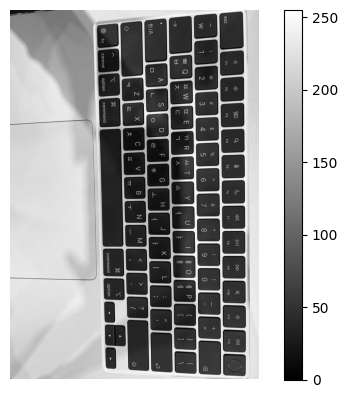

In [32]:
I = Image.open('/content/KakaoTalk_Photo_2026-11-06-15-27-53.jpeg').convert('L')
I = I.rotate(270, expand=True)
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

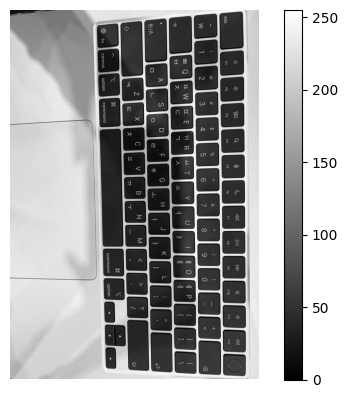

In [34]:
f_denoised = signal.medfilt2d(f,3)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

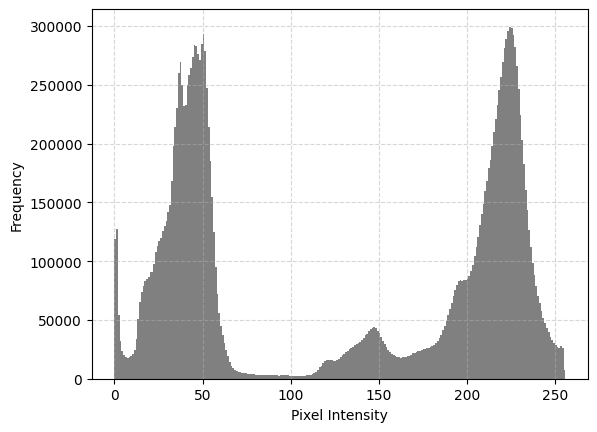

In [35]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

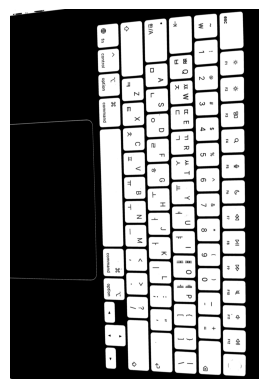

In [38]:
th_val = 85
f_mask = f_denoised < th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

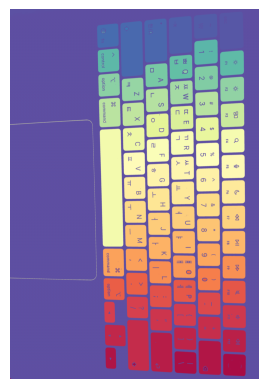

In [39]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

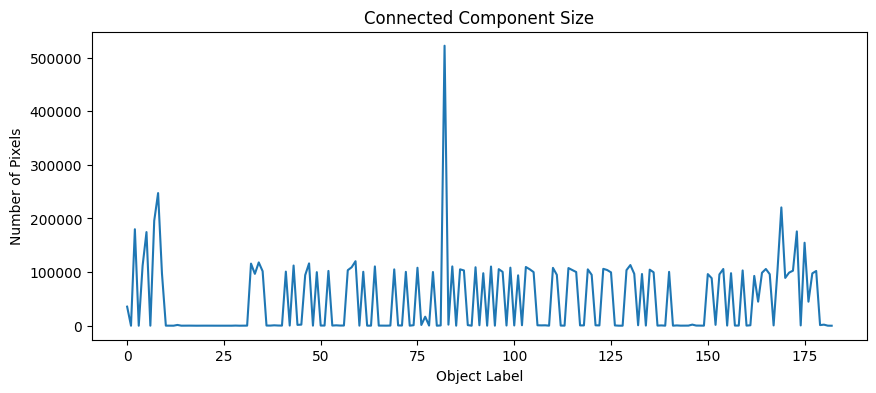

Filtered number of objects: 77


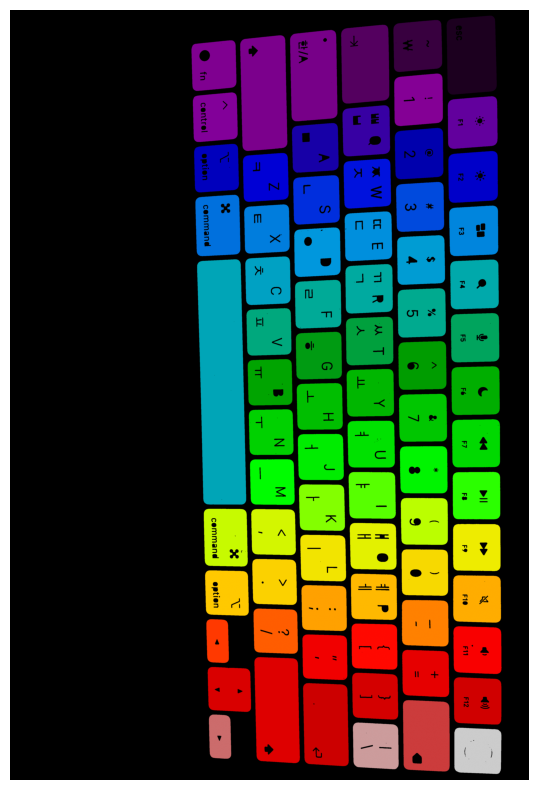

In [55]:
# 각 객체의 픽셀 수 계산
cc = np.bincount(f_label.ravel())

# 배경(label 0) 제외
cc[0] = 0

# 객체 크기 확인
plt.figure(figsize=(10, 4))
plt.plot(cc[1:])
plt.xlabel('Object Label')
plt.ylabel('Number of Pixels')
plt.title('Connected Component Size')
plt.show()

# 객체 크기 필터링
min_size = 10000
max_size = 600000

valid_labels = np.where((cc >= min_size) & (cc <= max_size))[0]

# 이미지 가장자리에 연결된 배경 객체 제거
border_labels = np.unique(np.concatenate([
    f_label[0, :],
    f_label[-1, :],
    f_label[:, 0],
    f_label[:, -1]
]))

valid_labels = np.setdiff1d(valid_labels, border_labels)

# 선택된 객체만 남기기
f_filtered = np.isin(f_label, valid_labels)

# 다시 라벨링
f_label_filtered, num_filtered = nd.label(f_filtered)

print('Filtered number of objects:', num_filtered)

plt.figure(figsize=(8, 10))
plt.imshow(f_label_filtered, cmap='nipy_spectral')
plt.axis('off')
plt.show()

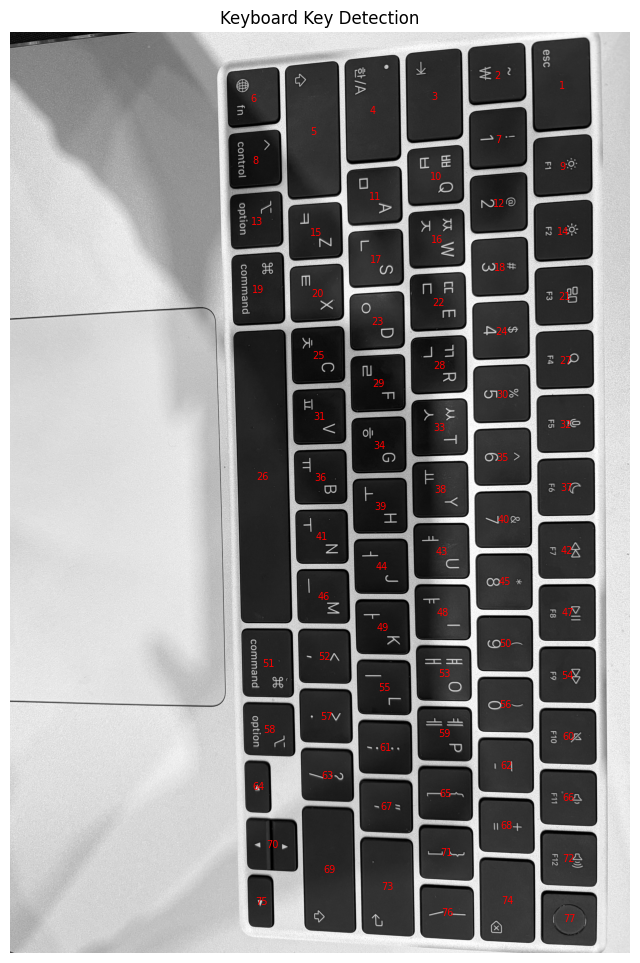

Total detected objects: 77


In [56]:
plt.figure(figsize=(8, 12))
plt.imshow(f, cmap='gray')

objects = nd.find_objects(f_label_filtered)

for i, obj in enumerate(objects):
    if obj is not None:
        y = (obj[0].start + obj[0].stop) / 2
        x = (obj[1].start + obj[1].stop) / 2

        plt.text(x, y, str(i+1),
                 color='red', fontsize=7,
                 ha='center', va='center')

plt.title('Keyboard Key Detection')
plt.axis('off')
plt.show()

print('Total detected objects:', num_filtered)

In [57]:
cc = np.zeros((nums-1,2))
for i in range(1,nums):
  cc[i-1,0] = i
  cc[i-1,1] = np.sum(labels==i)
  print(f'index: {int(cc[i-1,0])}, number of pixels: {int(cc[i-1,1])}')

index: 1, number of pixels: 35573
index: 2, number of pixels: 1
index: 3, number of pixels: 179943
index: 4, number of pixels: 10
index: 5, number of pixels: 112045
index: 6, number of pixels: 174661
index: 7, number of pixels: 78
index: 8, number of pixels: 195816
index: 9, number of pixels: 247381
index: 10, number of pixels: 97279
index: 11, number of pixels: 147
index: 12, number of pixels: 77
index: 13, number of pixels: 63
index: 14, number of pixels: 1454
index: 15, number of pixels: 73
index: 16, number of pixels: 179
index: 17, number of pixels: 183
index: 18, number of pixels: 45
index: 19, number of pixels: 38
index: 20, number of pixels: 116
index: 21, number of pixels: 114
index: 22, number of pixels: 54
index: 23, number of pixels: 57
index: 24, number of pixels: 121
index: 25, number of pixels: 48
index: 26, number of pixels: 121
index: 27, number of pixels: 53
index: 28, number of pixels: 37
index: 29, number of pixels: 279
index: 30, number of pixels: 39
index: 31, num

## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [61]:
cc_filtered = np.bincount(f_label_filtered.ravel())

ind_max = np.argmax(cc_filtered[1:]) + 1
ind_min = np.argmin(cc_filtered[1:]) + 1

print('Largest:', ind_max, cc_filtered[ind_max])
print('Smallest:', ind_min, cc_filtered[ind_min])

Largest: 26 522202
Smallest: 75 44837


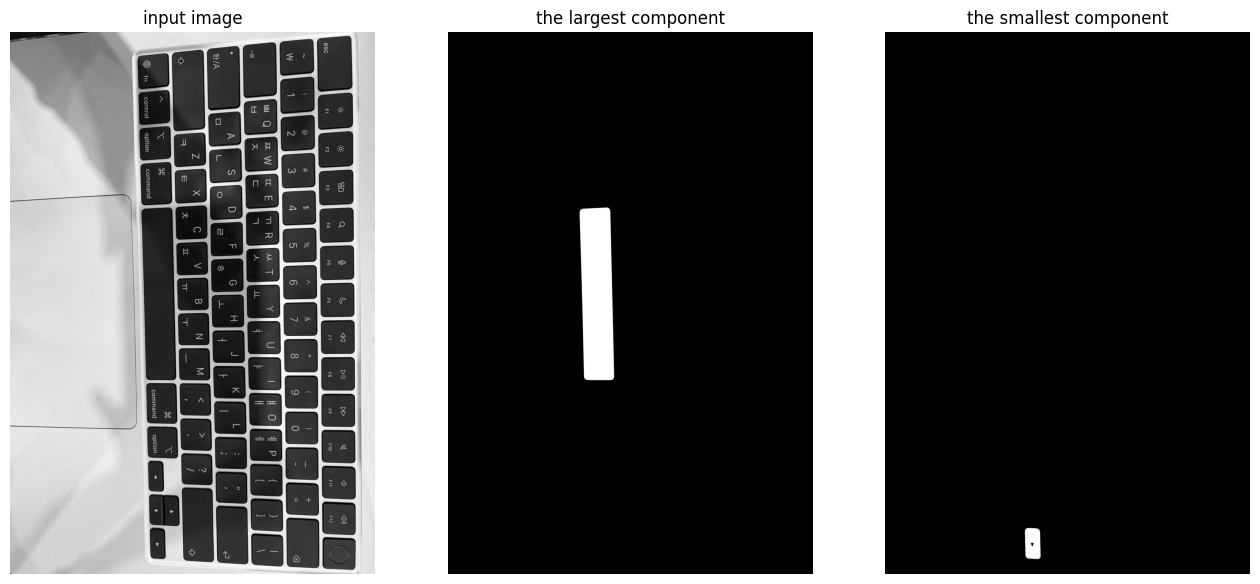

In [62]:
plt.figure(figsize=(16,9))

plt.subplot(131)
plt.imshow(f, cmap='gray')
plt.axis('off')
plt.title('input image')

plt.subplot(132)
plt.imshow(f_label_filtered == ind_max, cmap='gray')
plt.axis('off')
plt.title('the largest component')

plt.subplot(133)
plt.imshow(f_label_filtered == ind_min, cmap='gray')
plt.axis('off')
plt.title('the smallest component')

plt.show()